In [1]:
import simpy 
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../../code')
from utils import *

<div dir="rtl">

## עד עכשיו ראינו איך להשתמש בסימולציה לכל מיני שאלות בהסתברות

### עכשיו נעשה בהם שימוש למערכות מורכבות יותר.

### למשל:

### מערכות תורים: משרד הפנים, חדר מיון

### מערכות לוגיסטיות: amazon, תנובה, Intel

### מערכות ייצור: מפעל לייצור שבבים בNvidia, אסם

<div dir="rtl">

## לא נעים להגיד אבל...

### התוצאות המתמטיות שיש באקמיה לא מסוגלות לנתח את המערכות המרוכבות הללו בצורה אנליטית

## אז מה עושים???????

## ניחשתם נכון: סימולציה

### מה ההבדל בין פתרון מתמטי וסימולציה:

## פתרון מתמטי - מדויק ומהיר

## סימלוציה: איטי ולא מדויק

### אז למה כן סימולציה: כי זו הדרך היחידה לפתור בעיות

<div dir="rtl">

## דוגמה 1: בחירת שרת במערכת תורים

## נניח שיש לנו מערכת עם שרת יחיד, ואנחנו רוצים לבחור את השרת הזול ביותר האפשרי. שרת מהיר יותר יקר יותר, ולכן נרצה להעלות את קצב השירות רק עד כמה שצריך.


## הדרישה התפעולית שלנו היא שתוחלת זמן השהייה במערכת, כלומר זמן המתנה בתור ועוד זמן שירות, תהיה קטנה מ-3 יחידות זמן.

## את קצב ההגעה נשאיר קבוע, ובכל סימולציה נשנה את תוחלת זמן השירות.

### קצב הגעה: 0.8.

### הערה חשובה: אנחנו חייבים להקפיד על יציבות במערכת, כלומר קצב הגעה חייב להיות קטן מקצב שירות.

### אחרת: המערכת תתפוצץ. לא נוכל לעשות ניתוח סטציונרי.

</div>

In [2]:
import pandas as pd

ARRIVAL_RATE = 0.80
TARGET_MEAN_TIME_IN_SYSTEM = 3.0
WARMUP_CUSTOMERS = 1_000
MEASURED_CUSTOMERS = 8_000
TOTAL_CUSTOMERS = WARMUP_CUSTOMERS + MEASURED_CUSTOMERS
BASE_SEED = 2026

HYPER_ERLANG_PROBS = np.array([0.18, 0.24, 0.28, 0.30])
HYPER_ERLANG_SHAPES = np.array([5, 10, 15, 20])
HYPER_ERLANG_RELATIVE_MEANS = np.array([0.35, 0.80, 1.35, 2.10])

print(f"Total number of Erlang phases: {HYPER_ERLANG_SHAPES.sum()}")




Total number of Erlang phases: 50


<div dir="rtl">

### לפני שנריץ את מערכת התורים, נסתכל על הצפיפויות של ההתפלגויות שבהן נשתמש. התפלגות זמני בין-הגעות נשארת קבועה, ואילו התפלגות זמני השירות משתנה כאשר אנחנו בוחרים שרת מהיר או איטי יותר.

</div>

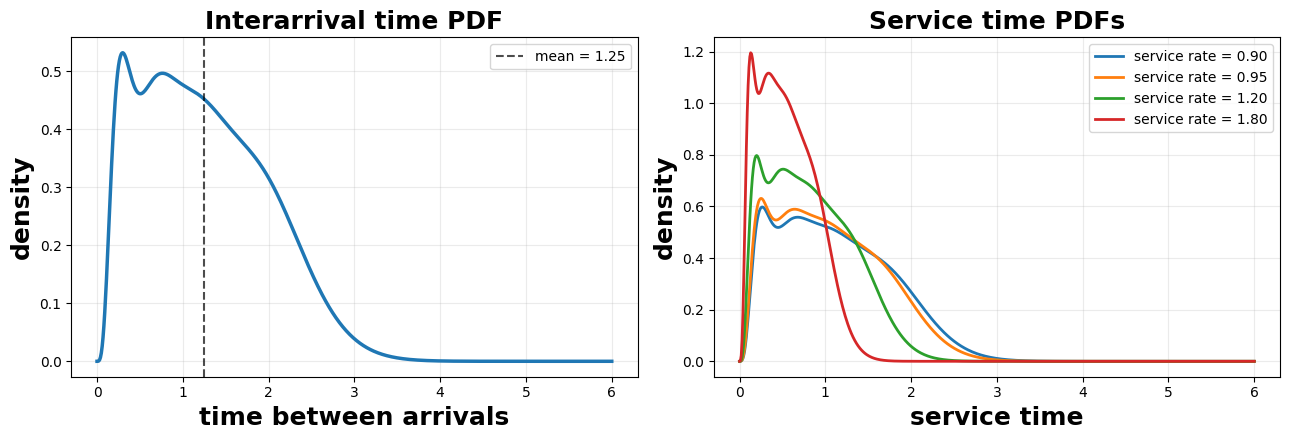

In [3]:
import math

x_values = np.linspace(0, 6, 600)
arrival_mean = 1 / ARRIVAL_RATE
representative_service_rates = [0.90, 0.95, 1.20, 1.80]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    x_values,
    hyper_erlang_pdf(
        x_values,
        target_mean=arrival_mean,
        probabilities=HYPER_ERLANG_PROBS,
        shapes=HYPER_ERLANG_SHAPES,
        relative_means=HYPER_ERLANG_RELATIVE_MEANS,
    ),
    color="tab:blue",
    linewidth=2.5,
)
axes[0].axvline(arrival_mean, color="black", linestyle="--", alpha=0.7, label=f"mean = {arrival_mean:.2f}")
axes[0].set_title("Interarrival time PDF", fontsize=18, fontweight="bold")
axes[0].set_xlabel("time between arrivals", fontsize=18, fontweight="bold")
axes[0].set_ylabel("density", fontsize=18, fontweight="bold")
axes[0].legend()
axes[0].grid(alpha=0.25)

for service_rate in representative_service_rates:
    mean_service_time = 1 / service_rate
    axes[1].plot(
        x_values,
        hyper_erlang_pdf(
            x_values,
            target_mean=mean_service_time,
            probabilities=HYPER_ERLANG_PROBS,
            shapes=HYPER_ERLANG_SHAPES,
            relative_means=HYPER_ERLANG_RELATIVE_MEANS,
        ),
        linewidth=2,
        label=f"service rate = {service_rate:.2f}",
    )

axes[1].set_title("Service time PDFs", fontsize=18, fontweight="bold")
axes[1].set_xlabel("service time", fontsize=18, fontweight="bold")
axes[1].set_ylabel("density", fontsize=18, fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


<div dir="rtl">
    
###  נריץ את הסימולציה עבור כמה קצבי שירות שונים. ככל שקצב השירות גדול יותר, השרת מהיר יותר ולכן יקר יותר. לכן נרצה למצוא את קצב השירות הקטן ביותר שמוריד את תוחלת זמן השהייה מתחת לקו האדום בגובה 3.

</div>

In [4]:
service_rates = np.round(np.linspace(0.90, 1.80, 19), 2)
results = []

for run_index, service_rate in enumerate(service_rates):
    mean_time_in_system = simulate_mean_time_in_system(
        service_rate=service_rate,
        seed=BASE_SEED + run_index,
        arrival_rate=ARRIVAL_RATE,
        warmup_customers=WARMUP_CUSTOMERS,
        measured_customers=MEASURED_CUSTOMERS,
        probabilities=HYPER_ERLANG_PROBS,
        shapes=HYPER_ERLANG_SHAPES,
        relative_means=HYPER_ERLANG_RELATIVE_MEANS,
    )
    results.append({
        "service_rate": service_rate,
        "mean_service_time": 1 / service_rate,
        "mean_time_in_system": mean_time_in_system,
    })

queue_results = pd.DataFrame(results)
feasible_servers = queue_results[
    queue_results["mean_time_in_system"] <= TARGET_MEAN_TIME_IN_SYSTEM
]

if feasible_servers.empty:
    print("No tested service rate satisfies the target.")
else:
    cheapest_feasible_server = feasible_servers.iloc[0]
    print(
        "Cheapest feasible server in this grid: "
        f"service rate = {cheapest_feasible_server['service_rate']:.2f}, "
        f"E[T] = {cheapest_feasible_server['mean_time_in_system']:.2f}"
    )

queue_results


Cheapest feasible server in this grid: service rate = 0.95, E[T] = 2.58


,service_rate,mean_service_time,mean_time_in_system
0,0.90,1.111111,3.487132
1,0.95,1.052632,2.584368
2,1.00,1.000000,2.094798
3,1.05,0.952381,1.848464
4,1.10,0.909091,1.599245
5,1.15,0.869565,1.493809
6,1.20,0.833333,1.289541
7,1.25,0.800000,1.222026
8,1.30,0.769231,1.135331
9,1.35,0.740741,1.036572


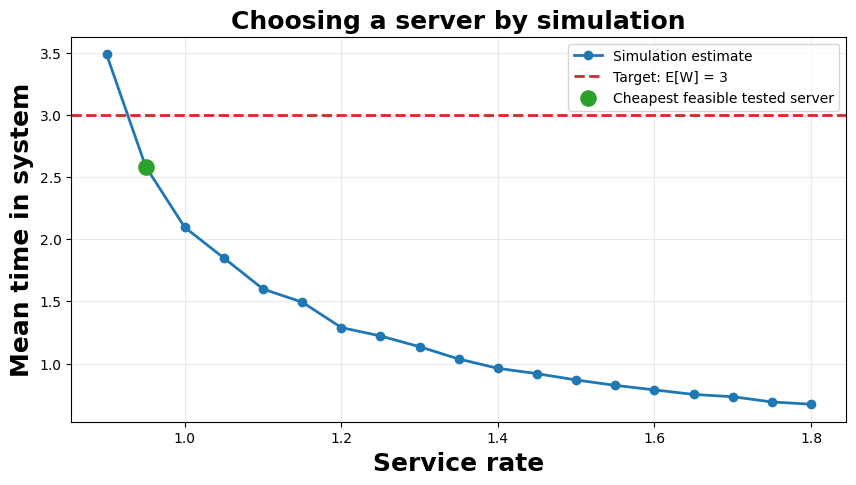

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(
    queue_results["service_rate"],
    queue_results["mean_time_in_system"],
    marker="o",
    linewidth=2,
    label="Simulation estimate",
)
plt.axhline(
    TARGET_MEAN_TIME_IN_SYSTEM,
    color="tab:red",
    linestyle="--",
    linewidth=2,
    label="Target: E[W] = 3",
)

if not feasible_servers.empty:
    plt.scatter(
        [cheapest_feasible_server["service_rate"]],
        [cheapest_feasible_server["mean_time_in_system"]],
        s=120,
        color="tab:green",
        zorder=3,
        label="Cheapest feasible tested server",
    )

plt.title("Choosing a server by simulation", fontweight  = 'bold', fontsize = 18)
plt.xlabel("Service rate", fontweight  = 'bold', fontsize = 18)
plt.ylabel("Mean time in system", fontweight  = 'bold', fontsize = 18)
plt.grid(alpha=0.25)
plt.legend()
plt.savefig('mean_time.png')
plt.show()


<div dir="rtl">

## דוגמה 2: אופטימיזציה תחת אילוץ - כמה שרתים צריך?


## כעת נסתכל על החלטה אחרת: במקום לבחור את מהירות השרת, נבחר כמה שרתים לפתוח.

## נניח שכל שרת עולה כסף, ולכן נרצה לפתוח כמה שפחות שרתים. מצד שני, אנחנו חייבים לעמוד באילוץ שירות: זמן ההמתנה הממוצע בתור צריך להיות קטן מ-2 יחידות זמן.

## כלומר הבעיה היא:


## **מצאו את מספר השרתים הקטן ביותר כך ש-** $E[W_q] < 2$


</div>

In [6]:

SERVER_COUNT_OPTIONS = np.arange(1, 9)
OPT_ARRIVAL_RATE = 2.95
OPT_SERVICE_RATE = 1.00
WAITING_TIME_TARGET = 2.0
OPT_WARMUP_CUSTOMERS = 1_000
OPT_MEASURED_CUSTOMERS = 8_000
OPT_TOTAL_CUSTOMERS = OPT_WARMUP_CUSTOMERS + OPT_MEASURED_CUSTOMERS
OPT_BASE_SEED = 4096



In [7]:
server_count_results = []

for run_index, server_count in enumerate(SERVER_COUNT_OPTIONS):
    server_count_results.append(
        simulate_server_count(
            server_count=server_count,
            seed=OPT_BASE_SEED + run_index,
            arrival_rate=OPT_ARRIVAL_RATE,
            service_rate=OPT_SERVICE_RATE,
            warmup_customers=OPT_WARMUP_CUSTOMERS,
            measured_customers=OPT_MEASURED_CUSTOMERS,
            probabilities=HYPER_ERLANG_PROBS,
            shapes=HYPER_ERLANG_SHAPES,
            relative_means=HYPER_ERLANG_RELATIVE_MEANS,
        )
    )

server_count_results = pd.DataFrame(server_count_results)
feasible_server_counts = server_count_results[
    server_count_results["mean_waiting_time"] <= WAITING_TIME_TARGET
]

if feasible_server_counts.empty:
    print("No tested number of servers satisfies the waiting-time target.")
else:
    cheapest_feasible_count = feasible_server_counts.iloc[0]
    print(
        "Smallest feasible number of servers: "
        f"c = {int(cheapest_feasible_count['servers'])}, "
        f"E[Wq] = {cheapest_feasible_count['mean_waiting_time']:.2f}"
    )

server_count_results


Smallest feasible number of servers: c = 4, E[Wq] = 0.11


,servers,utilization,mean_waiting_time,mean_time_in_system
0,1,2.950000,3322.474838,3323.473524
1,2,1.475000,804.416043,805.424103
2,3,0.983333,3.310794,4.309922
3,4,0.737500,0.106904,1.110571
4,5,0.590000,0.025769,1.017505
5,6,0.491667,0.004227,1.005325
6,7,0.421429,0.000263,0.993212
7,8,0.368750,0.000126,0.995954


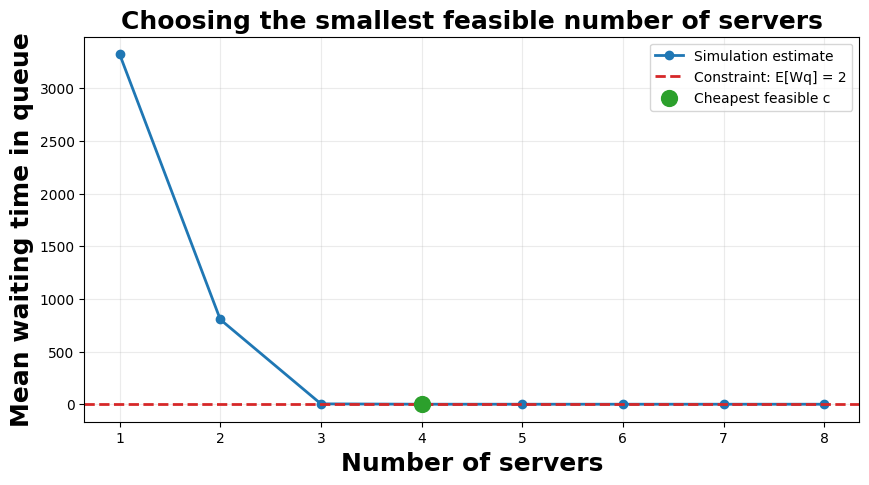

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(
    server_count_results["servers"],
    server_count_results["mean_waiting_time"],
    marker="o",
    linewidth=2,
    label="Simulation estimate",
)
plt.axhline(
    WAITING_TIME_TARGET,
    color="tab:red",
    linestyle="--",
    linewidth=2,
    label="Constraint: E[Wq] = 2",
)

if not feasible_server_counts.empty:
    plt.scatter(
        [cheapest_feasible_count["servers"]],
        [cheapest_feasible_count["mean_waiting_time"]],
        s=130,
        color="tab:green",
        zorder=3,
        label="Cheapest feasible c",
    )

plt.title("Choosing the smallest feasible number of servers", fontweight  = 'bold', fontsize = 18)
plt.xlabel("Number of servers", fontweight  = 'bold', fontsize = 18)
plt.ylabel("Mean waiting time in queue", fontweight  = 'bold', fontsize = 18)
plt.xticks(SERVER_COUNT_OPTIONS)
plt.grid(alpha=0.25)
plt.legend()

plt.show()


<div dir="rtl">

## נשים לב שהפונקציה מונוטונית יורדת. למה זה קורה?

## למה יש התכנסות מ-3 צרכנים? 